In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("stock.csv")
print("Shape:", df.shape)
df.head()

Shape: (240, 3)


,date,close,volume
0,2025-01-01,99.68,592896
1,2025-01-02,101.43,231931
2,2025-01-03,102.17,751394
3,2025-01-04,100.67,260365
4,2025-01-05,96.00,420685


In [3]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
print("Data from", df.index.min(), "to", df.index.max())
df.head()

Data from 2025-01-01 00:00:00 to 2025-08-28 00:00:00


,close,volume
date,,
2025-01-01,99.68,592896
2025-01-02,101.43,231931
2025-01-03,102.17,751394
2025-01-04,100.67,260365
2025-01-05,96.00,420685


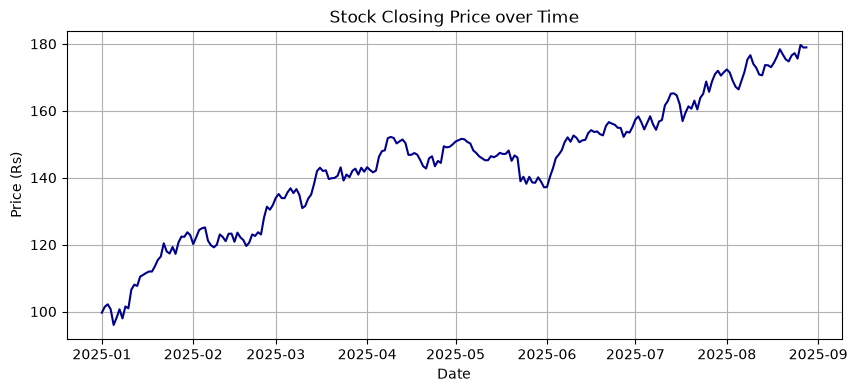

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["close"], color="darkblue")
plt.title("Stock Closing Price over Time")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.grid(True)
plt.show()

In [5]:
df["ma20"] = df["close"].rolling(20).mean()
df["ma50"] = df["close"].rolling(50).mean()
df[["close", "ma20", "ma50"]].tail(10)

,close,ma20,ma50
date,,,
2025-08-19,178.40,172.3980,166.0536
2025-08-20,176.83,172.6630,166.4424
2025-08-21,175.37,172.8140,166.7834
2025-08-22,174.76,172.9800,167.1468
2025-08-23,176.55,173.3580,167.5890
2025-08-24,177.23,173.8615,168.0058
2025-08-25,175.59,174.3210,168.3504
2025-08-26,179.68,174.8565,168.8258
2025-08-27,178.90,175.2195,169.3176


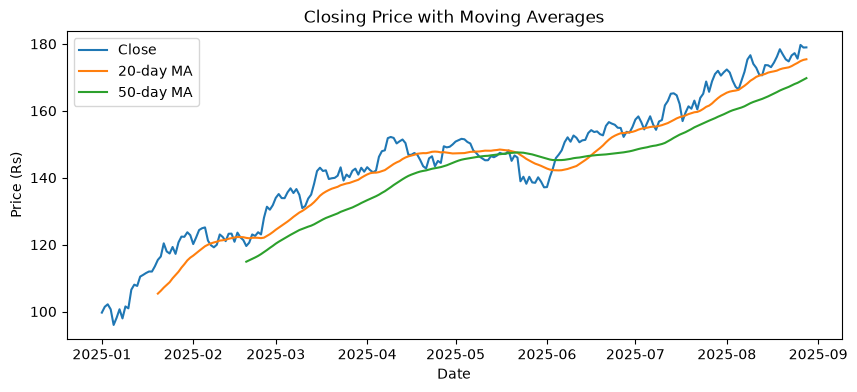

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["close"], label="Close")
plt.plot(df.index, df["ma20"], label="20-day MA")
plt.plot(df.index, df["ma50"], label="50-day MA")
plt.title("Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.show()

In [7]:
df["month"] = df.index.month
monthly = df.groupby("month")["close"].mean()
print("Average closing price by month:")
print(monthly)

Average closing price by month:
month
1    110.577742
2    123.288571
3    138.346774
4    147.082333
5    145.217097
6    151.381667
7    162.137097
8    173.938929
Name: close, dtype: float64


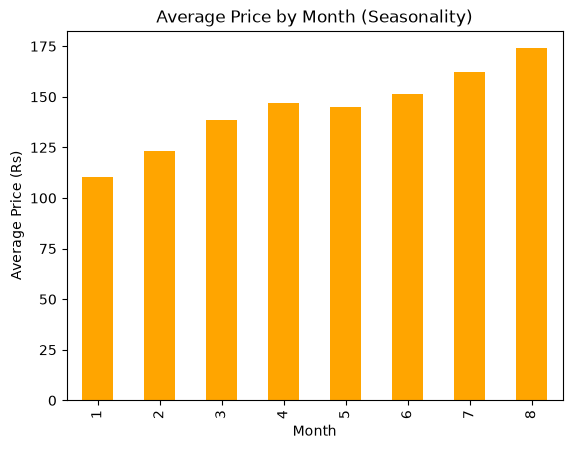

In [8]:
monthly.plot(kind="bar", color="orange")
plt.title("Average Price by Month (Seasonality)")
plt.xlabel("Month")
plt.ylabel("Average Price (Rs)")
plt.show()

Price-volume correlation: -0.038


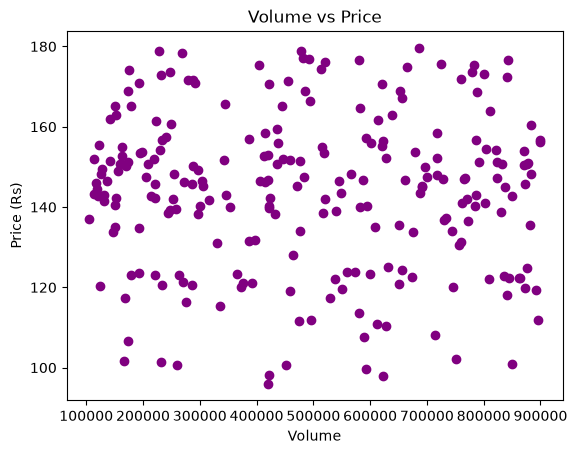

In [9]:
print("Price-volume correlation:", round(df["close"].corr(df["volume"]), 3))
plt.scatter(df["volume"], df["close"], color="purple")
plt.title("Volume vs Price")
plt.xlabel("Volume")
plt.ylabel("Price (Rs)")
plt.show()

In [10]:
smoothed = df["close"].ewm(alpha=0.3, adjust=False).mean()
trend = (smoothed.iloc[-1] - smoothed.iloc[-30]) / 30
future_dates = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=30)
forecast = smoothed.iloc[-1] + trend * np.arange(1, 31)
forecast_series = pd.Series(forecast, index=future_dates)
print("Forecast for the next 5 days:")
print(forecast_series.head())

Forecast for the next 5 days:
2025-08-29    178.330214
2025-08-30    178.618994
2025-08-31    178.907775
2025-09-01    179.196555
2025-09-02    179.485336
Freq: D, dtype: float64


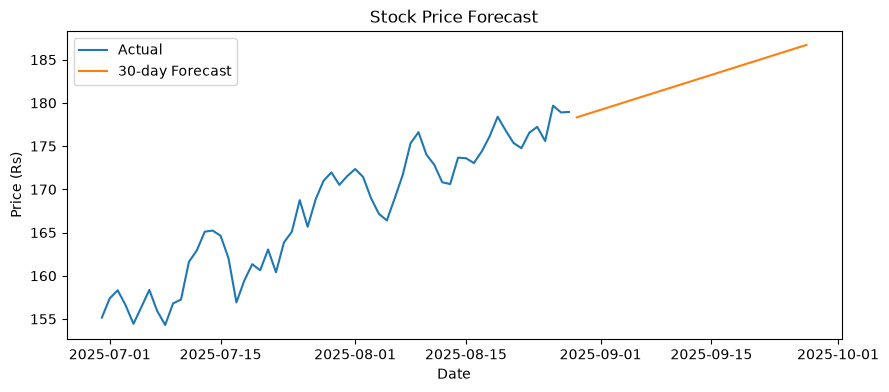

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(df.index[-60:], df["close"][-60:], label="Actual")
plt.plot(forecast_series.index, forecast_series.values, label="30-day Forecast")
plt.title("Stock Price Forecast")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.show()